1. Define the Prediction
Prediction:  
Predict whether a passenger survived based on their passenger class, sex, age, and fare. Survived is the target, and the other columns are features.

2. Import Libraries and Load Data
If you already have the Titanic dataset loaded, use that. Otherwise, you can use the Seaborn Titanic dataset:

In [15]:
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt

# Load Titanic dataset
df = sns.load_dataset("titanic")

# View the first 5 rows
df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [16]:
df.columns

Index(['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare',
       'embarked', 'class', 'who', 'adult_male', 'deck', 'embark_town',
       'alive', 'alone'],
      dtype='str')

3. Prepare the Data
We need these columns:
- pclass → Passenger class
- sex → Gender
- age → Age
- fare → Ticket fare
- survived → Target

In [17]:
# Select required columns
data = df[['pclass', 'sex', 'age', 'fare', 'survived']].copy()

# Remove rows with missing values
data = data.dropna()

# Convert sex into numbers
# female = 0, male = 1
data['sex'] = data['sex'].map({'female': 0, 'male': 1})

# Separate features and target
X = data[['pclass', 'sex', 'age', 'fare']]
y = data['survived']

print("Features:")
print(X.head())

print("\nTarget:")
print(y.head())

Features:
   pclass  sex   age     fare
0       3    1  22.0   7.2500
1       1    0  38.0  71.2833
2       3    0  26.0   7.9250
3       1    0  35.0  53.1000
4       3    1  35.0   8.0500

Target:
0    0
1    1
2    1
3    1
4    0
Name: survived, dtype: int64


4. Split the Data
We use:
- 80% for training
- 20% for testing
- random_state=42 so we get the same result every time
- stratify=y to maintain similar survival rates

In [18]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data size:", X_train.shape)
print("Testing data size:", X_test.shape)

Training data size: (571, 4)
Testing data size: (143, 4)


5. Set a Baseline
A baseline is a very simple prediction method.

Here, we always predict the most common outcome.

In [19]:
from sklearn.metrics import accuracy_score

# Find the most common outcome in training data
most_common = y_train.mode()[0]

# Predict the same outcome for every test passenger
baseline_predictions = [most_common] * len(y_test)

# Calculate baseline accuracy
baseline_accuracy = accuracy_score(y_test, baseline_predictions)

print("Most common outcome:", most_common)
print("Baseline Accuracy:", baseline_accuracy)

Most common outcome: 0
Baseline Accuracy: 0.5944055944055944


6. Train the Decision Tree Model

In [20]:
from sklearn.tree import DecisionTreeClassifier

# Create the model
model = DecisionTreeClassifier(
    max_depth=4,
    random_state=42
)

# Train the model using ONLY training data
model.fit(X_train, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",4
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at 

7. Evaluate the Model on Unseen Test Data

In [21]:
from sklearn.metrics import accuracy_score, confusion_matrix, mean_squared_error

# Make predictions on unseen test data
y_pred = model.predict(X_test)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

# Create confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Calculate MSE
mse = mean_squared_error(y_test, y_pred)

print("Decision Tree Accuracy:", accuracy)
print("\nBaseline Accuracy:", baseline_accuracy)
print("\nConfusion Matrix:")
print(cm)
print("\nMean Squared Error:", mse)

Decision Tree Accuracy: 0.7972027972027972

Baseline Accuracy: 0.5944055944055944

Confusion Matrix:
[[72 13]
 [16 42]]

Mean Squared Error: 0.20279720279720279


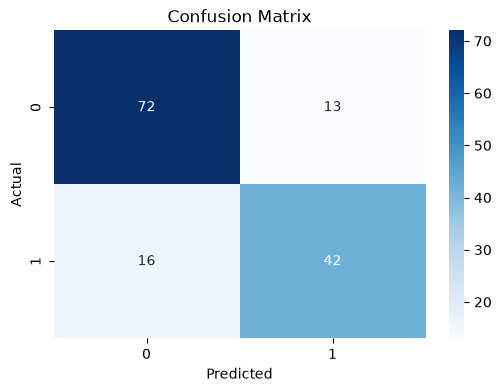

In [22]:
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")

plt.show()

8. Test Different Tree Depths

In [23]:
depths = range(1, 13)

train_accuracy = []
test_accuracy = []

for depth in depths:
    
    # Create model with current depth
    tree = DecisionTreeClassifier(
        max_depth=depth,
        random_state=42
    )
    
    # Train the model
    tree.fit(X_train, y_train)
    
    # Calculate training accuracy
    train_acc = tree.score(X_train, y_train)
    
    # Calculate testing accuracy
    test_acc = tree.score(X_test, y_test)
    
    # Store results
    train_accuracy.append(train_acc)
    test_accuracy.append(test_acc)

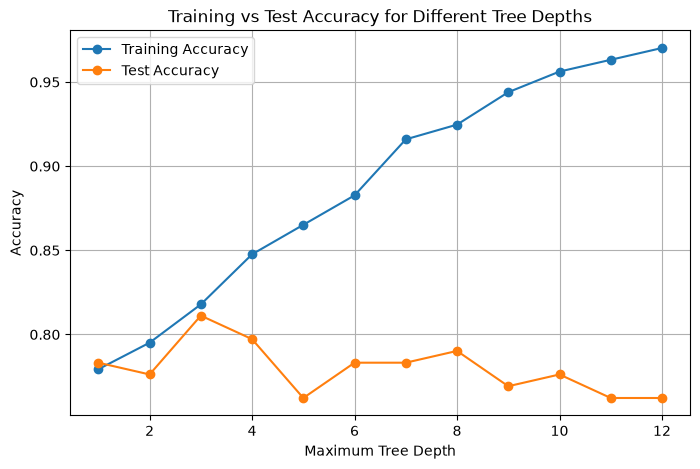

In [24]:
plt.figure(figsize=(8, 5))

plt.plot(depths, train_accuracy, marker='o', label='Training Accuracy')
plt.plot(depths, test_accuracy, marker='o', label='Test Accuracy')

plt.xlabel("Maximum Tree Depth")
plt.ylabel("Accuracy")
plt.title("Training vs Test Accuracy for Different Tree Depths")

plt.legend()
plt.grid(True)

plt.show()

9. Find the Most Important Features

In [25]:
# Get feature importance values
importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': model.feature_importances_
})

# Sort from most important to least important
importance = importance.sort_values(
    by='Importance',
    ascending=False
)

print(importance)

  Feature  Importance
1     sex    0.545075
0  pclass    0.235003
2     age    0.137570
3    fare    0.082352


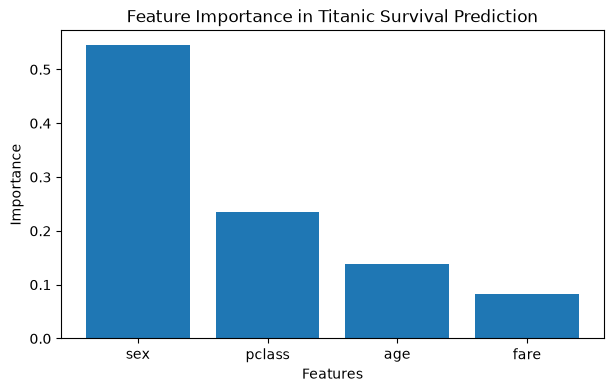

In [26]:
plt.figure(figsize=(7, 4))

plt.bar(importance['Feature'], importance['Importance'])

plt.xlabel("Features")
plt.ylabel("Importance")
plt.title("Feature Importance in Titanic Survival Prediction")

plt.show()

Conclusion

In this project, a Decision Tree model was used to predict whether a Titanic passenger survived based on their passenger class, sex, age, and fare. The dataset was divided into training and testing data so that the model could be tested on data it had not seen before.

The model was evaluated using accuracy, a confusion matrix, and Mean Squared Error (MSE). It was also compared with a simple baseline model that always predicted the most common outcome. Testing different tree depths showed that a very deep tree can lead to overfitting, where the model performs well on training data but not as well on new data.

Overall, this project helped demonstrate the importance of using unseen test data, comparing a model with a baseline, and selecting an appropriate model depth for better predictions.